# ThePower | Proyecto Final - Airbnb
## Análisis Exploratorio de Datos

## 1. Importación de Librerías

In [513]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import ast


## 2. Carga de Datos


### 2.1 Carga de listings

In [514]:
listings = pd.read_csv(
    'C:/Users/MARIHIDA/Desktop/Data_Analytics/Proyecto_final/data/listings.csv',
    encoding='latin1',
    low_memory=False,
    dtype={'host_response_time': 'string'}
)

listings.head()

,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
0,281420,"Beautiful Flat in le Village Montmartre, Paris",1466919,03/12/2011,"Paris, Ile-de-France, France",<NA>,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
1,3705183,39 m² Paris (Sacre Cur),10328771,29/11/2013,"Paris, Ile-de-France, France",<NA>,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
2,4082273,"Lovely apartment with Terrace, 60m2",19252768,31/07/2014,"Paris, Ile-de-France, France",<NA>,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
3,4797344,Cosy studio (close to Eiffel tower),10668311,17/12/2013,"Paris, Ile-de-France, France",<NA>,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
4,4823489,Close to Eiffel Tower - Beautiful flat : 2 rooms,24837558,14/12/2014,"Paris, Ile-de-France, France",<NA>,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f


In [515]:
listings.head()

,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
0,281420,"Beautiful Flat in le Village Montmartre, Paris",1466919,03/12/2011,"Paris, Ile-de-France, France",<NA>,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
1,3705183,39 m² Paris (Sacre Cur),10328771,29/11/2013,"Paris, Ile-de-France, France",<NA>,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
2,4082273,"Lovely apartment with Terrace, 60m2",19252768,31/07/2014,"Paris, Ile-de-France, France",<NA>,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
3,4797344,Cosy studio (close to Eiffel tower),10668311,17/12/2013,"Paris, Ile-de-France, France",<NA>,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
4,4823489,Close to Eiffel Tower - Beautiful flat : 2 rooms,24837558,14/12/2014,"Paris, Ile-de-France, France",<NA>,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f


### 2.2 Carga de review

In [516]:
review = pd.read_csv(
    'C:/Users/MARIHIDA/Desktop/Data_Analytics/Proyecto_final/data/review.csv', 
    low_memory=False)

review.head()

,listing_id,review_id,date,reviewer_id
0,5396,330894293,01/10/2018,138419097
1,5396,366234904,02/01/2019,75832568
2,5396,403009106,20/01/2019,76609105
3,5396,275059876,10/06/2018,146645051
4,5396,430988384,31/03/2019,13060762


## 3. Transformación y limpieza de Datos

### 3.1 Inspección inicial de las bases de datos




#### 3.1.1 Número de filas y columnas usando .shape


In [517]:
listings.shape

(60368, 33)

In [518]:
review.shape

(309143, 4)

#### 3.1.2 Tipos de datos usando .info


In [519]:
listings.info()

<class 'pandas.DataFrame'>
RangeIndex: 60368 entries, 0 to 60367
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   listing_id                   60368 non-null  int64  
 1   name                         60300 non-null  str    
 2   host_id                      60368 non-null  int64  
 3   host_since                   60316 non-null  str    
 4   host_location                60162 non-null  str    
 5   host_response_time           23778 non-null  string 
 6   host_response_rate           23778 non-null  float64
 7   host_acceptance_rate         29864 non-null  float64
 8   host_is_superhost            60316 non-null  str    
 9   host_total_listings_count    60316 non-null  float64
 10  host_has_profile_pic         60316 non-null  str    
 11  host_identity_verified       60316 non-null  str    
 12  neighbourhood                60368 non-null  str    
 13  district                   

In [520]:
review.info()

<class 'pandas.DataFrame'>
RangeIndex: 309143 entries, 0 to 309142
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   listing_id   309143 non-null  int64
 1   review_id    309143 non-null  int64
 2   date         309143 non-null  str  
 3   reviewer_id  309143 non-null  int64
dtypes: int64(3), str(1)
memory usage: 12.4 MB


#### 3.1.3 Números de valores faltantes en cada columna usando .isnull().sum()

In [521]:
listings.isnull().sum()

listing_id                         0
name                              68
host_id                            0
host_since                        52
host_location                    206
host_response_time             36590
host_response_rate             36590
host_acceptance_rate           30504
host_is_superhost                 52
host_total_listings_count         52
host_has_profile_pic              52
host_identity_verified            52
neighbourhood                      0
district                       52259
city                               0
latitude                           0
longitude                          0
property_type                      0
room_type                          0
accommodates                       0
bedrooms                       10152
amenities                          0
price                              0
minimum_nights                     0
maximum_nights                     0
review_scores_rating           17663
review_scores_accuracy         17737
r

In [522]:
review.isnull().sum()

listing_id     0
review_id      0
date           0
reviewer_id    0
dtype: int64

#### 3.1.4 Filas duplicadas usando .duplicated().sum()


In [523]:
listings.duplicated ().sum()

np.int64(0)

In [524]:
review.duplicated ().sum()

np.int64(0)

### 3.2 Eliminación de columnas innecesarias    

In [525]:
listings = listings.drop('host_since', axis=1)

In [526]:
listings = listings.drop('host_location', axis=1)

In [527]:
listings = listings.drop('district', axis=1)

### 3.3 Renombrar columnas

In [528]:
listings = listings.rename(columns={'price': 'price/night (EUR)'})

In [529]:
review = review.rename(columns={'date': 'review_date'})

In [530]:
listings.columns = listings.columns.str.title()

In [531]:
review.columns = review.columns.str.title()

### 3.4 Adaptar valores de variables

In [532]:
boolean_columns = [
    "Host_Is_Superhost",
    "Host_Identity_Verified",
    "Host_Has_Profile_Pic",
    "Instant_Bookable"
]

for col in boolean_columns:
    listings[col] = listings[col].map({
        "t": "Yes",
        "f": "No"
    }).fillna("Unknown")

In [533]:
mask = listings['Name'].astype(str).str.startswith('=')

print(listings.loc[mask, 'Name'])

1228    => Bastille up to 4 people!**
Name: Name, dtype: str


In [534]:
listings['Name'] = listings['Name'].str.lstrip('=').str.strip()

### 3.5 Gestión de valores faltantes


In [535]:
listings.isnull().sum()

Listing_Id                         0
Name                              68
Host_Id                            0
Host_Response_Time             36590
Host_Response_Rate             36590
Host_Acceptance_Rate           30504
Host_Is_Superhost                  0
Host_Total_Listings_Count         52
Host_Has_Profile_Pic               0
Host_Identity_Verified             0
Neighbourhood                      0
City                               0
Latitude                           0
Longitude                          0
Property_Type                      0
Room_Type                          0
Accommodates                       0
Bedrooms                       10152
Amenities                          0
Price/Night (Eur)                  0
Minimum_Nights                     0
Maximum_Nights                     0
Review_Scores_Rating           17663
Review_Scores_Accuracy         17737
Review_Scores_Cleanliness      17721
Review_Scores_Checkin          17752
Review_Scores_Communication    17720
R

In [536]:
resultado = pd.DataFrame({
    "Missing Count": listings.isna().sum(),
    "Missing %": listings.isna().mean().mul(100),
    "Not Missing %": listings.notna().mean().mul(100)
}).round(2)
display(resultado)

,Missing Count,Missing %,Not Missing %
Listing_Id,0,0.00,100.00
Name,68,0.11,99.89
Host_Id,0,0.00,100.00
Host_Response_Time,36590,60.61,39.39
Host_Response_Rate,36590,60.61,39.39
Host_Acceptance_Rate,30504,50.53,49.47
Host_Is_Superhost,0,0.00,100.00
Host_Total_Listings_Count,52,0.09,99.91
Host_Has_Profile_Pic,0,0.00,100.00
Host_Identity_Verified,0,0.00,100.00


In [537]:
# Bedrooms → mediana
listings['Bedrooms'] = listings['Bedrooms'].fillna(
    listings['Bedrooms'].median()
).astype('int64')


In [538]:
import re

def normalize(col):
    return re.sub(r"[^a-z0-9]+", "_", str(col).strip().lower()).strip("_")

columns = {normalize(col): col for col in listings.columns}

print("Available columns:", listings.columns.tolist())

name_col = columns.get("name")
id_col = columns.get("listing_id") or columns.get("listingid")

if name_col is None or id_col is None:
    print("Couldn't identify both columns. Check the available columns above.")
else:
    name_text = listings[name_col].astype("string")
    empty_name = (
        name_text.isna()
        | name_text.str.strip().eq("").fillna(False)
    )

    empty_listings = listings.loc[empty_name, [id_col, name_col]]
    display(empty_listings)
    print("Listing IDs:", empty_listings[id_col].tolist())

Available columns: ['Listing_Id', 'Name', 'Host_Id', 'Host_Response_Time', 'Host_Response_Rate', 'Host_Acceptance_Rate', 'Host_Is_Superhost', 'Host_Total_Listings_Count', 'Host_Has_Profile_Pic', 'Host_Identity_Verified', 'Neighbourhood', 'City', 'Latitude', 'Longitude', 'Property_Type', 'Room_Type', 'Accommodates', 'Bedrooms', 'Amenities', 'Price/Night (Eur)', 'Minimum_Nights', 'Maximum_Nights', 'Review_Scores_Rating', 'Review_Scores_Accuracy', 'Review_Scores_Cleanliness', 'Review_Scores_Checkin', 'Review_Scores_Communication', 'Review_Scores_Location', 'Review_Scores_Value', 'Instant_Bookable']


,Listing_Id,Name
388,4661616,NaN
1260,11811541,NaN
1441,12355699,NaN
2047,6076734,NaN
2439,9102328,NaN
2708,7298789,NaN
2730,7743656,NaN
2766,10511155,NaN
2861,6632475,NaN
2872,7185047,NaN


Listing IDs: [4661616, 11811541, 12355699, 6076734, 9102328, 7298789, 7743656, 10511155, 6632475, 7185047, 13769813, 7838471, 9103179, 4843112, 3047718, 13080979, 9487232, 7169268, 9192741, 3853848, 7450252, 9877496, 9917778, 4295818, 7604290, 3122511, 13040422, 6920597, 7589778, 9967138, 4370230, 6754615, 2221003, 6641583, 9883860, 3042602, 4246166, 9325951, 6148415, 4040049, 11558351, 12534182, 13785804, 11768107, 12529240, 3176928, 7660987, 7128012, 4973237, 9489550, 3128739, 3293506, 6027660, 2930312, 3059885, 3114294, 9062468, 3174811, 3631353, 8843799, 10423583, 1933579, 6951672, 1615764, 4209595, 5566391, 9787590, 2540638]


In [539]:
name_text = listings[name_col].astype("string")
empty_name = name_text.isna() | name_text.str.strip().eq("").fillna(False)
fill_mask = empty_name & listings[id_col].notna()

listings.loc[fill_mask, name_col] = listings.loc[fill_mask, id_col].astype("string")

print("Nombres rellenados:", int(fill_mask.sum()))

resultado = pd.DataFrame({
    "Missing Count": listings.isna().sum(),
    "Missing %": listings.isna().mean().mul(100),
    "Not Missing %": listings.notna().mean().mul(100)
}).round(2)

display(resultado)

Nombres rellenados: 68


,Missing Count,Missing %,Not Missing %
Listing_Id,0,0.00,100.00
Name,0,0.00,100.00
Host_Id,0,0.00,100.00
Host_Response_Time,36590,60.61,39.39
Host_Response_Rate,36590,60.61,39.39
Host_Acceptance_Rate,30504,50.53,49.47
Host_Is_Superhost,0,0.00,100.00
Host_Total_Listings_Count,52,0.09,99.91
Host_Has_Profile_Pic,0,0.00,100.00
Host_Identity_Verified,0,0.00,100.00


### 3.6 Unión de Dataframes

In [540]:
print(f"IDs únicos listings: {listings['Listing_Id'].nunique()}")
print(f"IDs únicos reviews: {review['Listing_Id'].nunique()}")

IDs únicos listings: 60368
IDs únicos reviews: 12777


In [541]:
all_reviews_have_listing = review['Listing_Id'].isin(listings['Listing_Id']).all()

print(f"¿Todos los listing_id de reviews están en listings? {all_reviews_have_listing}")

¿Todos los listing_id de reviews están en listings? True


In [542]:
common_ids = set(listings['Listing_Id']).intersection(set(review['Listing_Id']))

print(f"IDs en común: {len(common_ids)}")

IDs en común: 12777


In [543]:
data = review.merge(
    listings,
    on='Listing_Id',
    how='left'
)

In [544]:
print(f"Listings únicos: {listings['Listing_Id'].nunique()}")
print(f"Filas listings: {len(listings)}")

Listings únicos: 60368
Filas listings: 60368


In [545]:
data.head()

,Listing_Id,Review_Id,Review_Date,Reviewer_Id,Name,Host_Id,Host_Response_Time,Host_Response_Rate,Host_Acceptance_Rate,Host_Is_Superhost,...,Minimum_Nights,Maximum_Nights,Review_Scores_Rating,Review_Scores_Accuracy,Review_Scores_Cleanliness,Review_Scores_Checkin,Review_Scores_Communication,Review_Scores_Location,Review_Scores_Value,Instant_Bookable
0,5396,330894293,01/10/2018,138419097,Explore the heart of old Paris,7903,within an hour,0.88,0.96,No,...,3,1125,90.0,9.0,9.0,9.0,10.0,10.0,8.0,Yes
1,5396,366234904,02/01/2019,75832568,Explore the heart of old Paris,7903,within an hour,0.88,0.96,No,...,3,1125,90.0,9.0,9.0,9.0,10.0,10.0,8.0,Yes
2,5396,403009106,20/01/2019,76609105,Explore the heart of old Paris,7903,within an hour,0.88,0.96,No,...,3,1125,90.0,9.0,9.0,9.0,10.0,10.0,8.0,Yes
3,5396,275059876,10/06/2018,146645051,Explore the heart of old Paris,7903,within an hour,0.88,0.96,No,...,3,1125,90.0,9.0,9.0,9.0,10.0,10.0,8.0,Yes
4,5396,430988384,31/03/2019,13060762,Explore the heart of old Paris,7903,within an hour,0.88,0.96,No,...,3,1125,90.0,9.0,9.0,9.0,10.0,10.0,8.0,Yes


In [546]:
listings.shape

(60368, 30)

In [547]:
listings.dtypes

Listing_Id                       int64
Name                               str
Host_Id                          int64
Host_Response_Time              string
Host_Response_Rate             float64
Host_Acceptance_Rate           float64
Host_Is_Superhost                  str
Host_Total_Listings_Count      float64
Host_Has_Profile_Pic               str
Host_Identity_Verified             str
Neighbourhood                      str
City                               str
Latitude                       float64
Longitude                      float64
Property_Type                      str
Room_Type                          str
Accommodates                     int64
Bedrooms                         int64
Amenities                          str
Price/Night (Eur)                int64
Minimum_Nights                   int64
Maximum_Nights                   int64
Review_Scores_Rating           float64
Review_Scores_Accuracy         float64
Review_Scores_Cleanliness      float64
Review_Scores_Checkin    

In [548]:
data.to_excel('listings_review_merged.xlsx', index=False)

In [549]:
import os

In [550]:
os.getcwd()

'c:\\Users\\MARIHIDA\\Desktop\\Data_Analytics\\Proyecto_final\\scr'

In [551]:
data.head()

,Listing_Id,Review_Id,Review_Date,Reviewer_Id,Name,Host_Id,Host_Response_Time,Host_Response_Rate,Host_Acceptance_Rate,Host_Is_Superhost,...,Minimum_Nights,Maximum_Nights,Review_Scores_Rating,Review_Scores_Accuracy,Review_Scores_Cleanliness,Review_Scores_Checkin,Review_Scores_Communication,Review_Scores_Location,Review_Scores_Value,Instant_Bookable
0,5396,330894293,01/10/2018,138419097,Explore the heart of old Paris,7903,within an hour,0.88,0.96,No,...,3,1125,90.0,9.0,9.0,9.0,10.0,10.0,8.0,Yes
1,5396,366234904,02/01/2019,75832568,Explore the heart of old Paris,7903,within an hour,0.88,0.96,No,...,3,1125,90.0,9.0,9.0,9.0,10.0,10.0,8.0,Yes
2,5396,403009106,20/01/2019,76609105,Explore the heart of old Paris,7903,within an hour,0.88,0.96,No,...,3,1125,90.0,9.0,9.0,9.0,10.0,10.0,8.0,Yes
3,5396,275059876,10/06/2018,146645051,Explore the heart of old Paris,7903,within an hour,0.88,0.96,No,...,3,1125,90.0,9.0,9.0,9.0,10.0,10.0,8.0,Yes
4,5396,430988384,31/03/2019,13060762,Explore the heart of old Paris,7903,within an hour,0.88,0.96,No,...,3,1125,90.0,9.0,9.0,9.0,10.0,10.0,8.0,Yes


## 4. Análisis Exploratorio de Datos

### 4.1 Análisis de Variables de la muestra

In [552]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 309143 entries, 0 to 309142
Data columns (total 33 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Listing_Id                   309143 non-null  int64  
 1   Review_Id                    309143 non-null  int64  
 2   Review_Date                  309143 non-null  str    
 3   Reviewer_Id                  309143 non-null  int64  
 4   Name                         309143 non-null  str    
 5   Host_Id                      309143 non-null  int64  
 6   Host_Response_Time           148705 non-null  string 
 7   Host_Response_Rate           148705 non-null  float64
 8   Host_Acceptance_Rate         203995 non-null  float64
 9   Host_Is_Superhost            309143 non-null  str    
 10  Host_Total_Listings_Count    308991 non-null  float64
 11  Host_Has_Profile_Pic         309143 non-null  str    
 12  Host_Identity_Verified       309143 non-null  str    
 13  Neighbourh

In [553]:
data.describe()

,Listing_Id,Review_Id,Reviewer_Id,Host_Id,Host_Response_Rate,Host_Acceptance_Rate,Host_Total_Listings_Count,Latitude,Longitude,Accommodates,...,Price/Night (Eur),Minimum_Nights,Maximum_Nights,Review_Scores_Rating,Review_Scores_Accuracy,Review_Scores_Cleanliness,Review_Scores_Checkin,Review_Scores_Communication,Review_Scores_Location,Review_Scores_Value
count,3.091430e+05,3.091430e+05,3.091430e+05,3.091430e+05,148705.000000,203995.000000,308991.000000,309143.000000,309143.000000,309143.000000,...,309143.000000,309143.000000,309143.0,308670.000000,308062.000000,308064.000000,308045.000000,308060.000000,308044.000000,308042.000000
mean,1.324678e+07,2.883373e+08,7.748274e+07,5.338641e+07,0.875020,0.844341,8.361179,48.863534,2.344176,3.382296,...,111.293634,4.638824,1125.0,92.936981,9.626017,9.245686,9.720275,9.736019,9.782216,9.237205
std,8.716319e+06,1.848276e+08,7.592776e+07,6.766562e+07,0.247041,0.264996,40.634210,0.016555,0.030292,1.790357,...,114.168455,19.604422,0.0,4.937550,0.539263,0.751160,0.506405,0.488937,0.462774,0.612652
min,5.396000e+03,4.824000e+03,3.240000e+02,7.903000e+03,0.000000,0.000000,0.000000,48.816700,2.238380,1.000000,...,10.000000,1.000000,1125.0,20.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,5.391304e+06,1.304940e+08,1.943206e+07,9.049581e+06,0.890000,0.830000,1.000000,48.852190,2.327410,2.000000,...,65.000000,2.000000,1125.0,90.000000,9.000000,9.000000,9.000000,10.000000,10.000000,9.000000
50%,1.266141e+07,2.672325e+08,4.941170e+07,2.536218e+07,0.990000,0.980000,1.000000,48.863640,2.348000,3.000000,...,85.000000,2.000000,1125.0,94.000000,10.000000,9.000000,10.000000,10.000000,10.000000,9.000000
75%,2.018124e+07,4.406627e+08,1.168466e+08,6.489040e+07,1.000000,1.000000,1.000000,48.875010,2.364050,4.000000,...,122.000000,3.000000,1125.0,97.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
max,3.075944e+07,7.304991e+08,3.873467e+08,3.735826e+08,1.000000,1.000000,1105.000000,48.901290,2.445620,16.000000,...,6742.000000,1001.000000,1125.0,100.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


In [554]:
data.columns = data.columns.astype(str).str.strip()

static_cols = [
    "City", "Neighbourhood", "Property_Type", "Room_Type",
    "Price/Night (Eur)", "Price_Category", "Accommodates", "Bedrooms",
    "Minimum_Nights", "Maximum_Nights", "Review_Scores_Rating",
    "Host_Is_Superhost", "Instant_Bookable", "Amenities"
]

required = ["Listing_Id", "Review_Id", "Review_Date"] + static_cols
missing = [c for c in required if c not in data.columns]
if missing:
    raise KeyError(f"Missing columns in data: {missing}")

listing_level = data.groupby("Listing_Id")[static_cols].first()

review_count = (
    data.groupby("Listing_Id")["Review_Id"]
    .nunique()
    .rename("Review_Count")
)

listing_level = listing_level.join(review_count).reset_index()

for col in [
    "Price/Night (Eur)", "Accommodates", "Bedrooms",
    "Minimum_Nights", "Maximum_Nights", "Review_Scores_Rating"
]:
    listing_level[col] = pd.to_numeric(listing_level[col], errors="coerce")

price_col = "Price/Night (Eur)"

KeyError: "Missing columns in data: ['Price_Category']"

In [ ]:
print("Alojamientos únicos:", data["Listing_Id"].nunique())


Alojamientos únicos: 12777


### 4.2 Variable precio

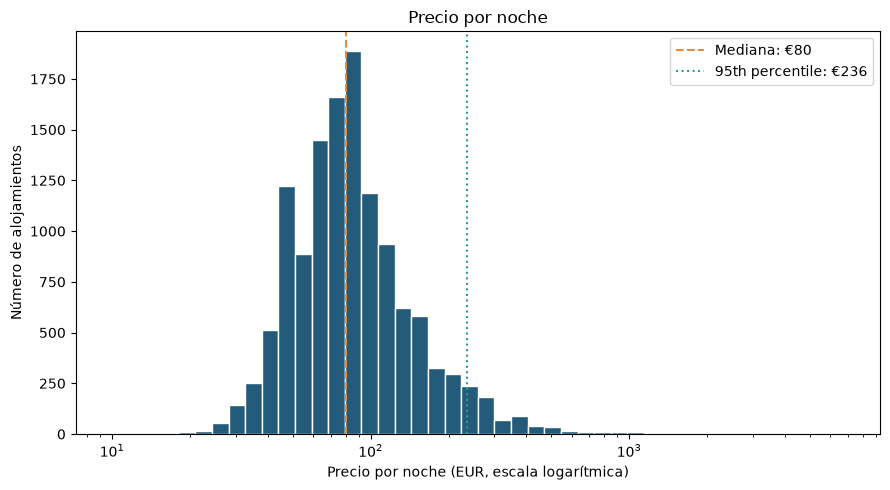

In [ ]:
price = listing_level.loc[
    listing_level[price_col].notna() & (listing_level[price_col] > 0),
    price_col
]

bins = np.logspace(np.log10(price.min()), np.log10(price.max()), 45)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(price, bins=bins, color="#245A7A", edgecolor="white")
ax.set_xscale("log")
ax.axvline(price.median(), color="#E58B3A", linestyle="--",
           label=f"Mediana: €{price.median():.0f}")
ax.axvline(price.quantile(.95), color="#2A9D8F", linestyle=":",
           label=f"95th percentile: €{price.quantile(.95):.0f}")
ax.set_title("Precio por noche")
ax.set_xlabel("Precio por noche (EUR, escala logarítmica)")
ax.set_ylabel("Número de alojamientos")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
cols = ["Price/Night (Eur)", "Bedrooms", "Accommodates"]

listing_unique = (
    data.groupby("Listing_Id")[cols]
    .first()
    .reset_index()
)

for col in cols:
    listing_unique[col] = pd.to_numeric(
        listing_unique[col], errors="coerce"
    )

# Mediana del precio por número de dormitorios
precio_por_dormitorios = (
    listing_unique.dropna(subset=["Bedrooms", "Price/Night (Eur)"])
    .groupby("Bedrooms")["Price/Night (Eur)"]
    .agg(Anuncios="count", Mediana="median")
)

display(precio_por_dormitorios.loc[[1, 2, 3, 4]].round(2))

# Correlaciones de Spearman
correlaciones = listing_unique[
    ["Price/Night (Eur)", "Accommodates", "Bedrooms"]
].corr(method="spearman")

print("Precio–capacidad:",
      round(correlaciones.loc["Price/Night (Eur)", "Accommodates"], 3))
print("Precio–dormitorios:",
      round(correlaciones.loc["Price/Night (Eur)", "Bedrooms"], 3))
print("Capacidad–dormitorios:",
      round(correlaciones.loc["Accommodates", "Bedrooms"], 3))

,Anuncios,Mediana
Bedrooms,,
1,9928,70.0
2,2075,120.0
3,631,195.0
4,122,250.0


Precio–capacidad: 0.526
Precio–dormitorios: 0.504
Capacidad–dormitorios: 0.636


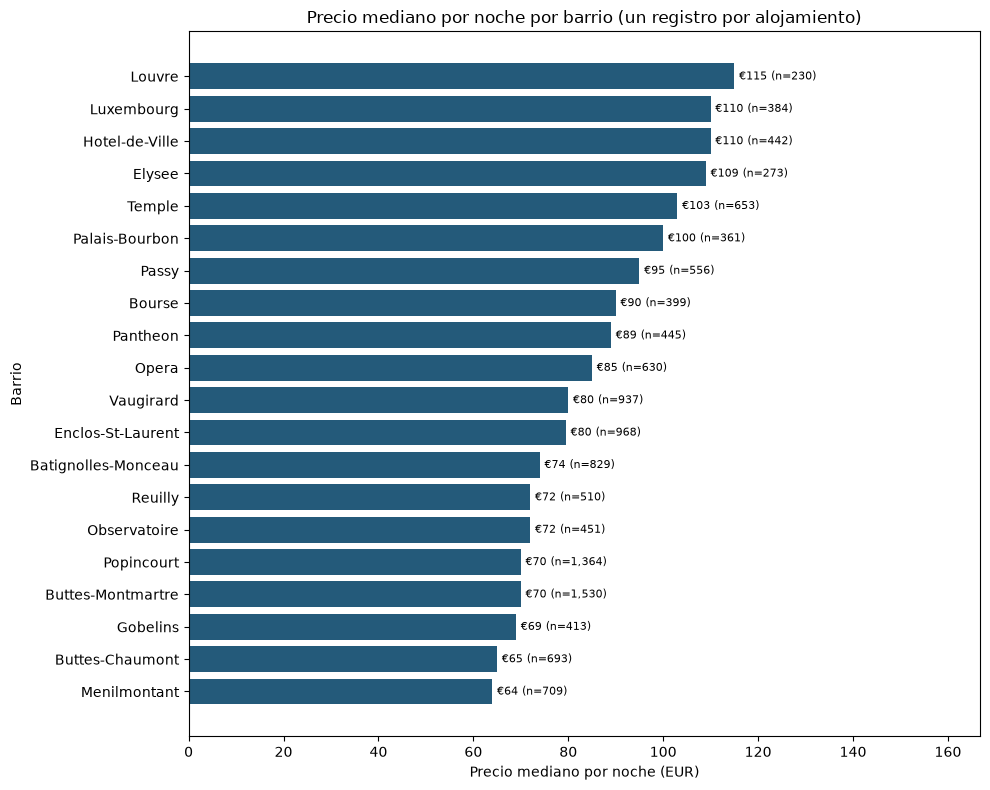

In [ ]:
neighbourhood = (
    listing_level.groupby("Neighbourhood")[price_col]
    .agg(median="median", n="count")
    .sort_values("median")
)

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(neighbourhood.index, neighbourhood["median"], color="#245A7A")

for bar, n in zip(bars, neighbourhood["n"]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f"€{bar.get_width():.0f} (n={n:,})",
            va="center", fontsize=8)

ax.set_xlim(0, neighbourhood["median"].max() * 1.45)
ax.set_title("Precio mediano por noche por barrio (un registro por alojamiento)")
ax.set_xlabel("Precio mediano por noche (EUR)")
ax.set_ylabel("Barrio")
plt.tight_layout()
plt.show()

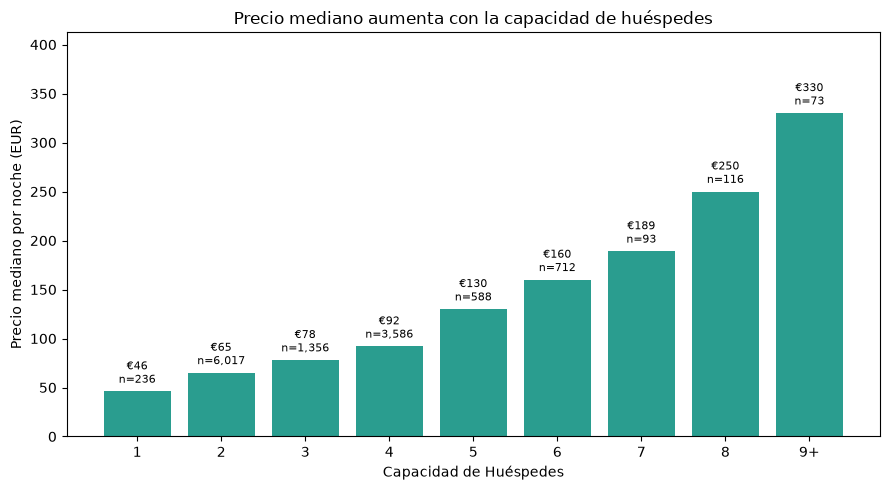

In [ ]:
listing_level["Capacity_Group"] = np.where(
    listing_level["Accommodates"] >= 9,
    "9+",
    listing_level["Accommodates"].astype("Int64").astype(str)
)

capacity = (
    listing_level.groupby("Capacity_Group")[price_col]
    .agg(median="median", n="count")
)

order = [str(i) for i in range(1, 9)] + ["9+"]
capacity = capacity.reindex([x for x in order if x in capacity.index]).dropna()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(capacity.index, capacity["median"], color="#2A9D8F")

for bar, n in zip(bars, capacity["n"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            f"€{bar.get_height():.0f}\nn={n:,}",
            ha="center", va="bottom", fontsize=8)

ax.set_ylim(0, capacity["median"].max() * 1.25)
ax.set_title("Precio mediano aumenta con la capacidad de huéspedes")
ax.set_xlabel("Capacidad de Huéspedes")
ax.set_ylabel("Precio mediano por noche (EUR)")
plt.tight_layout()
plt.show()

### 4.3 Variable ratings

In [ ]:
ratings = (
    data.groupby("Listing_Id")["Review_Scores_Rating"]
    .first()
)

ratings = pd.to_numeric(ratings, errors="coerce").dropna()

median_rating = ratings.median()
mean_rating = ratings.mean()
modes = ratings.mode()
most_frequent_rating = modes.iloc[0]
mode_percent = (ratings == most_frequent_rating).mean() * 100

print(f"Alojamientos con valoración: {len(ratings):,}")
print(f"Valoración mediana: {median_rating:.0f}/100")
print(f"Valoración media: {mean_rating:.2f}/100")
print(
    f"Valoración más frecuente: {most_frequent_rating:.0f}/100 "
    f"({mode_percent:.1f}%)"
)

Alojamientos con valoración: 12,378
Valoración mediana: 95/100
Valoración media: 92.86/100
Valoración más frecuente: 100/100 (21.7%)


In [ ]:
por_anuncio = data.groupby("Listing_Id").agg(
    Rating=("Review_Scores_Rating", "first"),
    Superhost=("Host_Is_Superhost", "first"),
    Instant_Bookable=("Instant_Bookable", "first")
)

por_anuncio["Rating"] = pd.to_numeric(
    por_anuncio["Rating"], errors="coerce"
)

resumen_superhost = (
    por_anuncio.groupby("Superhost")["Rating"]
    .agg(n="count", Mediana="median", Media="mean")
)
display(resumen_superhost.round(2))

resumen_reserva = (
    por_anuncio.groupby("Instant_Bookable")["Rating"]
    .agg(n="count", Mediana="median", Media="mean")
)
display(resumen_reserva.round(2))

,n,Mediana,Media
Superhost,,,
No,11170,94.0,92.47
Unknown,5,90.0,87.00
Yes,1203,97.0,96.50


,n,Mediana,Media
Instant_Bookable,,,
No,9300,95.0,93.29
Yes,3078,93.0,91.54


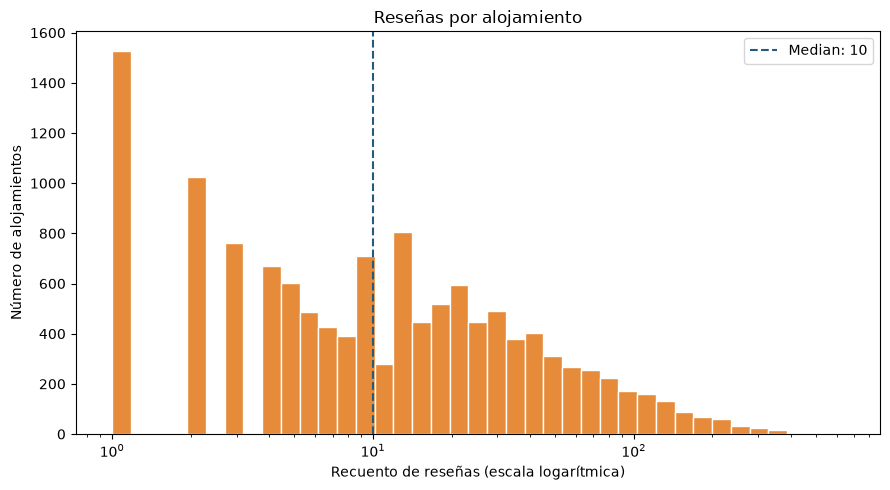

In [ ]:
reviews_per_listing = listing_level["Review_Count"]
bins = np.logspace(0, np.log10(reviews_per_listing.max()), 40)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(reviews_per_listing, bins=bins, color="#E58B3A", edgecolor="white")
ax.set_xscale("log")
ax.axvline(reviews_per_listing.median(), color="#245A7A",
           linestyle="--", label=f"Median: {reviews_per_listing.median():.0f}")
ax.set_title("Reseñas por alojamiento")
ax.set_xlabel("Recuento de reseñas (escala logarítmica)")
ax.set_ylabel("Número de alojamientos")
ax.legend()
plt.tight_layout()
plt.show()

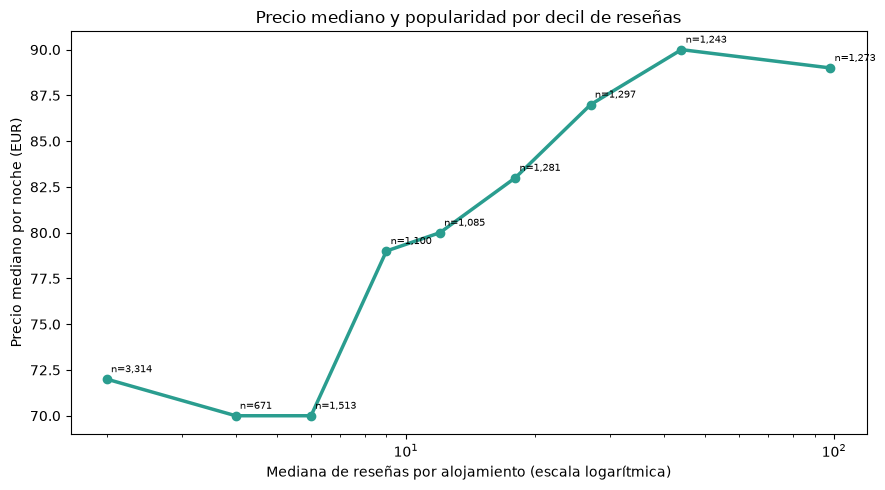

In [ ]:
deciles = listing_level[["Review_Count", price_col]].dropna().copy()
deciles["Review_Decile"] = pd.qcut(
    deciles["Review_Count"], q=10, duplicates="drop"
)

decile_summary = (
    deciles.groupby("Review_Decile", observed=True)
    .agg(
        median_reviews=("Review_Count", "median"),
        median_price=(price_col, "median"),
        n=(price_col, "count")
    )
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(decile_summary["median_reviews"], decile_summary["median_price"],
        marker="o", color="#2A9D8F", linewidth=2.5)
ax.set_xscale("log")
ax.set_title("Precio mediano y popularidad por decil de reseñas")
ax.set_ylabel("Precio mediano por noche (EUR)")
ax.set_xlabel("Mediana de reseñas por alojamiento (escala logarítmica)")

for _, row in decile_summary.iterrows():
    ax.annotate(f"n={int(row['n']):,}",
                (row["median_reviews"], row["median_price"]),
                xytext=(3, 5), textcoords="offset points", fontsize=7)

plt.tight_layout()
plt.show()

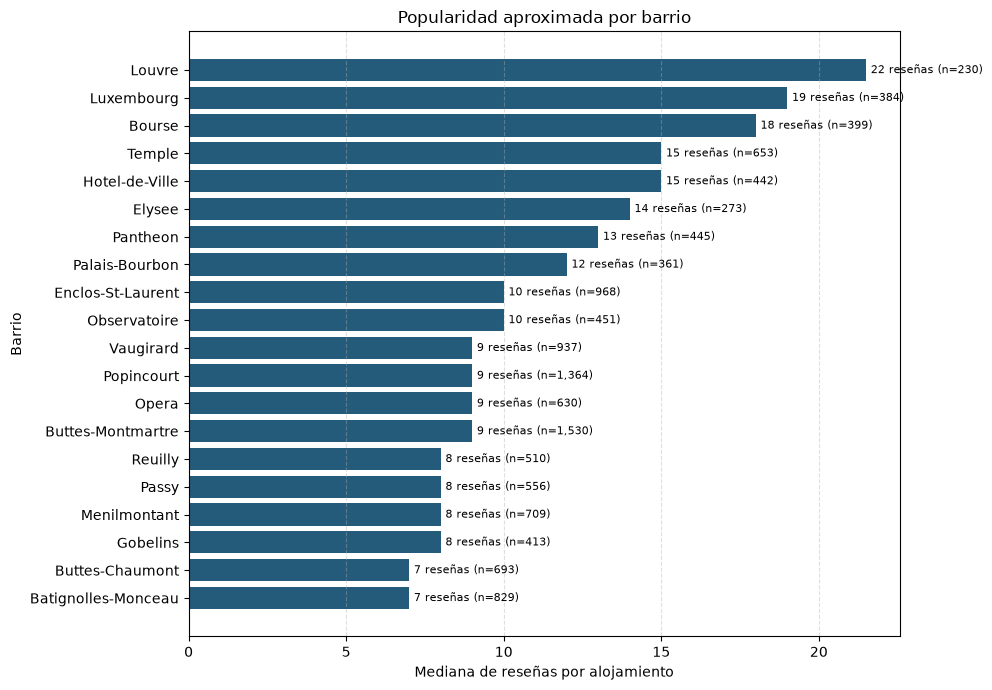

In [ ]:
reviews_per_listing = (
    data.groupby("Listing_Id")
    .agg(
        Neighbourhood=("Neighbourhood", "first"),
        Review_Count=("Review_Id", "nunique")
    )
)


by_neighbourhood = (
    reviews_per_listing.groupby("Neighbourhood")
    .agg(
        Listings=("Review_Count", "size"),
        Median_Reviews_per_Listing=("Review_Count", "median")
    )
    .sort_values("Median_Reviews_per_Listing")
)


fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(
    by_neighbourhood.index,
    by_neighbourhood["Median_Reviews_per_Listing"],
    color="#245A7A"
)

for bar, (_, row) in zip(bars, by_neighbourhood.iterrows()):
    ax.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.0f} reseñas (n={int(row['Listings']):,})",
        va="center",
        fontsize=8
    )

ax.set_title("Popularidad aproximada por barrio")
ax.set_xlabel("Mediana de reseñas por alojamiento")
ax.set_ylabel("Barrio")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### 4.4 Variable de tiempo

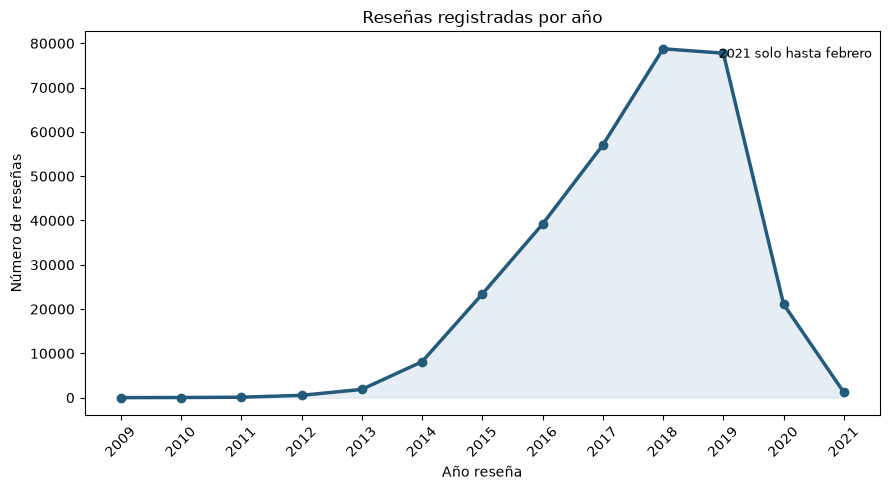

In [ ]:
review_events = data.drop_duplicates("Review_Id").copy()
review_events["Review_Date"] = pd.to_datetime(
    review_events["Review_Date"], dayfirst=True, errors="coerce"
)
review_events["Review_Year"] = review_events["Review_Date"].dt.year

yearly_reviews = review_events.groupby("Review_Year").size().sort_index()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(yearly_reviews.index, yearly_reviews.values,
        marker="o", color="#245A7A", linewidth=2.5)
ax.fill_between(yearly_reviews.index, yearly_reviews.values,
                color="#DCE8EF", alpha=.7)
ax.set_title("Reseñas registradas por año")
ax.set_xlabel("Año reseña")
ax.set_ylabel("Número de reseñas")
ax.set_xticks(yearly_reviews.index)
ax.tick_params(axis="x", rotation=45)
ax.text(.99, .96, "2021 solo hasta febrero",
        transform=ax.transAxes, ha="right", va="top", fontsize=9)
plt.tight_layout()
plt.show()

### 4.6 Variables por anfitrión

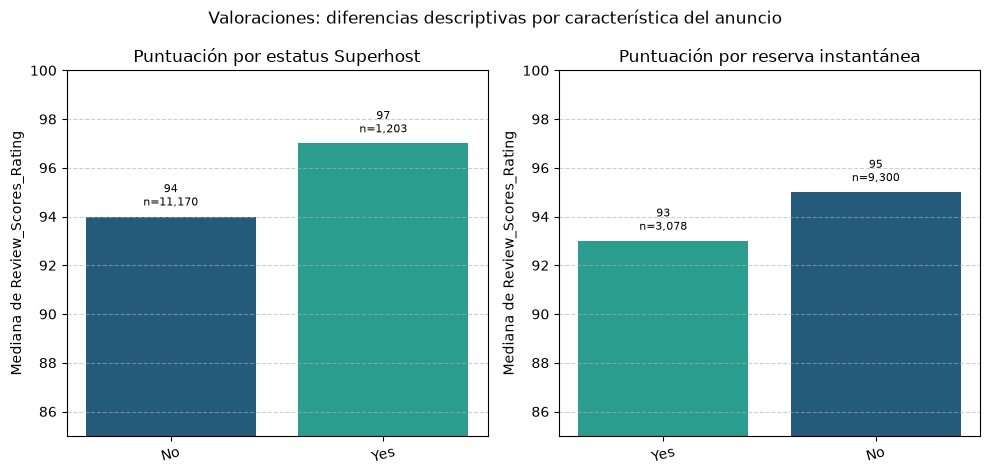

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))

comparaciones = [
    ("Host_Is_Superhost", ["No", "Yes"],
     "Puntuación por estatus Superhost"),
    ("Instant_Bookable", ["Yes", "No"],
     "Puntuación por reserva instantánea")
]

for ax, (col, orden, titulo) in zip(axes, comparaciones):
    resumen = (
        listing_level.groupby(col)["Review_Scores_Rating"]
        .agg(mediana="median", n="count")
        .reindex(orden)
        .dropna()
    )

    colores = ["#2A9D8F" if categoria == "Yes" else "#245A7A"
               for categoria in resumen.index]

    barras = ax.bar(
        resumen.index.astype(str),
        resumen["mediana"],
        color=colores
    )

    for barra, (_, fila) in zip(barras, resumen.iterrows()):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 0.3,
            f"{fila['mediana']:.0f}\nn={int(fila['n']):,}",
            ha="center",
            va="bottom",
            fontsize=8
        )

    ax.set_ylim(85, 100)  # Coincide con el gráfico del informe
    ax.set_title(titulo)
    ax.set_ylabel("Mediana de Review_Scores_Rating")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", linestyle="--", alpha=0.6)

fig.suptitle(
    "Valoraciones: diferencias descriptivas por característica del anuncio"
)
plt.tight_layout()
plt.show()

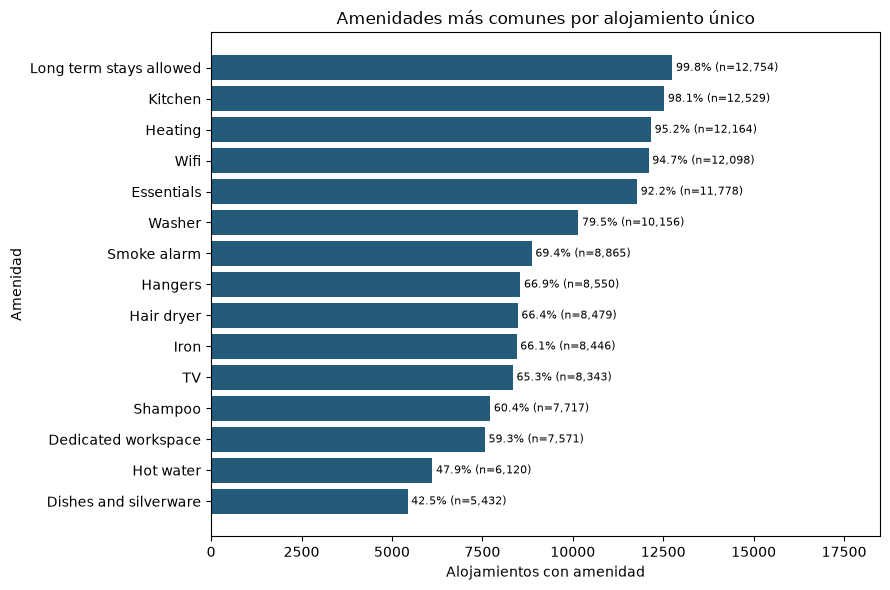

In [ ]:
def parse_amenities(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str) or not value.strip():
        return []
    try:
        result = ast.literal_eval(value)
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError):
        try:
            result = json.loads(value)
            return result if isinstance(result, list) else []
        except (ValueError, TypeError):
            return []

amenities_by_listing = listing_level["Amenities"].map(parse_amenities)

amenity_counts = Counter(
    amenity
    for items in amenities_by_listing
    for amenity in set(items)
)

top_amenities = pd.Series(dict(amenity_counts)).nlargest(15).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top_amenities.index, top_amenities.values, color="#245A7A")

for bar, count in zip(bars, top_amenities.values):
    pct = count / len(listing_level) * 100
    ax.text(bar.get_width() + 100,
            bar.get_y() + bar.get_height() / 2,
            f"{pct:.1f}% (n={count:,})",
            va="center", fontsize=8)

ax.set_xlim(0, top_amenities.max() * 1.45)
ax.set_title("Amenidades más comunes por alojamiento único")
ax.set_xlabel("Alojamientos con amenidad")
ax.set_ylabel("Amenidad")
plt.tight_layout()
plt.show()

### 4.7 Matriz de correlaciones

In [ ]:
corr_data = listing_level.copy()

# Codificar variables categóricas binarias; "Unknown" queda como faltante
corr_data["Superhost_Yes"] = corr_data["Host_Is_Superhost"].map(
    {"Yes": 1, "No": 0}
)
corr_data["Instant_Bookable_Yes"] = corr_data["Instant_Bookable"].map(
    {"Yes": 1, "No": 0}
)

corr_cols = [
    "Price/Night (Eur)",
    "Review_Count",
    "Review_Scores_Rating",
    "Accommodates",
    "Bedrooms",
    "Minimum_Nights",
    "Superhost_Yes",
    "Instant_Bookable_Yes"
]

corr_data[corr_cols] = corr_data[corr_cols].apply(
    pd.to_numeric, errors="coerce"
)

corr = corr_data[corr_cols].corr(method="spearman")
display(corr.round(2))

,Price/Night (Eur),Review_Count,Review_Scores_Rating,Accommodates,Bedrooms,Minimum_Nights,Superhost_Yes,Instant_Bookable_Yes
Price/Night (Eur),1.00,0.17,0.12,0.53,0.50,0.03,0.13,0.07
Review_Count,0.17,1.00,-0.14,0.05,0.02,-0.00,0.34,0.10
Review_Scores_Rating,0.12,-0.14,1.00,-0.02,0.04,0.12,0.15,-0.12
Accommodates,0.53,0.05,-0.02,1.00,0.64,0.00,0.02,0.05
Bedrooms,0.50,0.02,0.04,0.64,1.00,0.05,0.01,0.02
Minimum_Nights,0.03,-0.00,0.12,0.00,0.05,1.00,0.01,-0.09
Superhost_Yes,0.13,0.34,0.15,0.02,0.01,0.01,1.00,0.03
Instant_Bookable_Yes,0.07,0.10,-0.12,0.05,0.02,-0.09,0.03,1.00


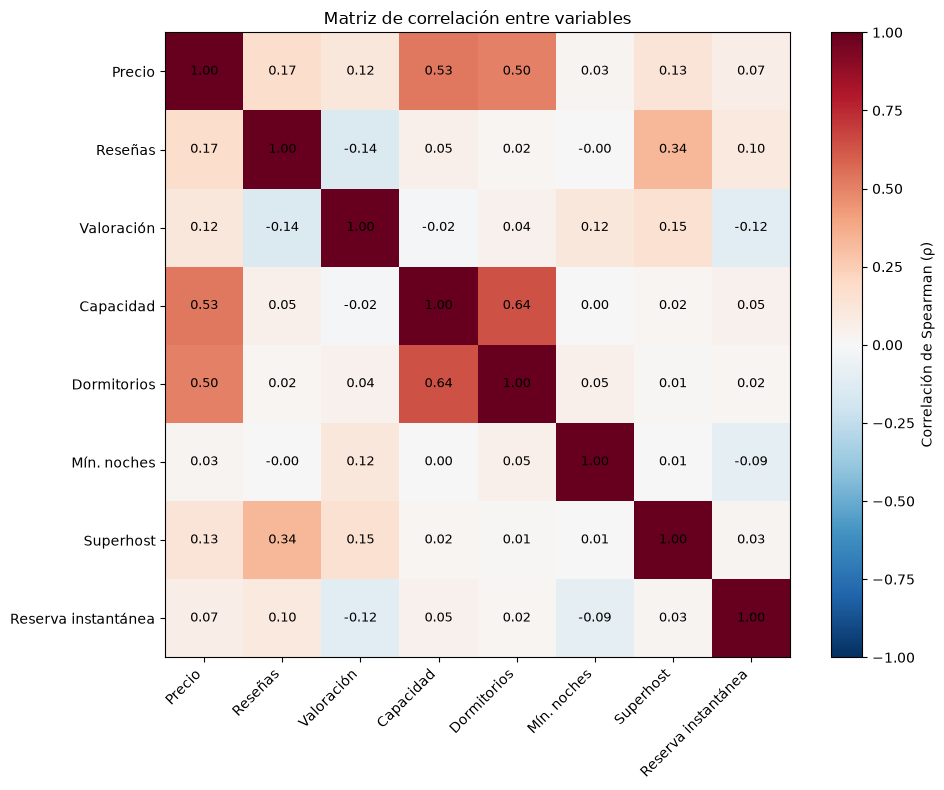

In [ ]:
labels = {
    "Price/Night (Eur)": "Precio",
    "Review_Count": "Reseñas",
    "Review_Scores_Rating": "Valoración",
    "Accommodates": "Capacidad",
    "Bedrooms": "Dormitorios",
    "Minimum_Nights": "Mín. noches",
    "Superhost_Yes": "Superhost",
    "Instant_Bookable_Yes": "Reserva instantánea"
}

corr_plot = corr.rename(index=labels, columns=labels)

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr_plot, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr_plot.columns)))
ax.set_xticklabels(corr_plot.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr_plot.index)))
ax.set_yticklabels(corr_plot.index)

for i in range(corr_plot.shape[0]):
    for j in range(corr_plot.shape[1]):
        value = corr_plot.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9)

fig.colorbar(image, ax=ax, label="Correlación de Spearman (ρ)")
ax.set_title("Matriz de correlación entre variables")
plt.tight_layout()
plt.show()

### 4.8 Modelo Exploratorio

In [555]:
data.columns = data.columns.astype(str).str.strip()

if "Review_Id" not in data.columns:
    raise ValueError(
        "data debe ser la tabla combinada que contiene Review_Id."
    )

variables = [
    "Price/Night (Eur)", "Neighbourhood", "Accommodates", "Bedrooms",
    "Minimum_Nights", "Review_Scores_Rating",
    "Host_Is_Superhost", "Instant_Bookable"
]

faltan = [c for c in ["Listing_Id", "Review_Id"] + variables
          if c not in data.columns]
if faltan:
    raise KeyError(f"Faltan estas columnas: {faltan}")

listing_level = data.groupby("Listing_Id")[variables].first()

review_count = (
    data.groupby("Listing_Id")["Review_Id"]
    .nunique()
    .rename("Review_Count")
)

listing_level = listing_level.join(review_count).reset_index()

In [556]:
num_cols = [
    "Price/Night (Eur)", "Accommodates", "Bedrooms",
    "Minimum_Nights", "Review_Scores_Rating", "Review_Count"
]

for col in num_cols:
    listing_level[col] = pd.to_numeric(listing_level[col], errors="coerce")

# Preparar muestra y transformaciones
model_data = listing_level.copy()
model_data = model_data[model_data["Price/Night (Eur)"] > 0].copy()

model_data["log_price"] = np.log(model_data["Price/Night (Eur)"])
model_data["log_min_nights"] = np.log1p(model_data["Minimum_Nights"])
model_data["log_reviews"] = np.log1p(model_data["Review_Count"])

required = [
    "log_price", "Neighbourhood", "Accommodates", "Bedrooms",
    "log_min_nights", "Review_Scores_Rating",
    "Host_Is_Superhost", "Instant_Bookable", "log_reviews"
]
model_data = model_data.dropna(subset=required).copy()

# Ordenar categorías para que las referencias sean reproducibles:
# barrio alfabéticamente primero; Superhost No; reserva instantánea No.
neighbourhood_levels = sorted(
    model_data["Neighbourhood"].dropna().astype(str).unique()
)
model_data["Neighbourhood"] = pd.Categorical(
    model_data["Neighbourhood"], categories=neighbourhood_levels
)
model_data["Host_Is_Superhost"] = pd.Categorical(
    model_data["Host_Is_Superhost"], categories=["No", "Unknown", "Yes"]
)
model_data["Instant_Bookable"] = pd.Categorical(
    model_data["Instant_Bookable"], categories=["No", "Yes"]
)

# Matriz de diseño: Price_Category se omite porque deriva del precio
numeric_predictors = [
    "Accommodates", "Bedrooms", "log_min_nights",
    "Review_Scores_Rating", "log_reviews"
]
categorical_predictors = [
    "Neighbourhood", "Host_Is_Superhost", "Instant_Bookable"
]

X_df = pd.get_dummies(
    model_data[numeric_predictors + categorical_predictors],
    columns=categorical_predictors,
    drop_first=True,
    dtype=float
)
X_df.insert(0, "Intercept", 1.0)

X = X_df.to_numpy(dtype=float)
y = model_data["log_price"].to_numpy(dtype=float)

# Coeficientes OLS
beta = np.linalg.lstsq(X, y, rcond=None)[0]
residuos = y - X @ beta

# Covarianza y errores estándar HC3
bread = np.linalg.pinv(X.T @ X)
leverage = np.einsum("ij,jk,ik->i", X, bread, X)
residuos_ajustados = residuos / np.clip(1 - leverage, 1e-12, None)

meat = X.T @ (X * (residuos_ajustados ** 2)[:, None])
cov_hc3 = bread @ meat @ bread

se_hc3 = np.sqrt(np.clip(np.diag(cov_hc3), 0, None))
z = beta / se_hc3

# Valores p bilaterales aproximados usando la distribución normal estándar
p_values = np.array([
    math.erfc(abs(float(valor)) / math.sqrt(2))
    for valor in z
])

# R² y R² ajustado
n, k = X.shape
sse = np.sum(residuos ** 2)
sst = np.sum((y - y.mean()) ** 2)
r2 = 1 - sse / sst
r2_ajustado = 1 - (1 - r2) * (n - 1) / (n - k)

print("Anuncios incluidos:", n)
print(f"R²: {r2:.3f}")
print(f"R² ajustado: {r2_ajustado:.3f}")

Anuncios incluidos: 12378
R²: 0.493
R² ajustado: 0.492


In [557]:
resultados = pd.DataFrame({
    "Coef. log": beta,
    "HC3 SE": se_hc3,
    "z": z,
    "p-value": p_values,
    "IC95% log inferior": beta - 1.96 * se_hc3,
    "IC95% log superior": beta + 1.96 * se_hc3
}, index=X_df.columns)

terminos = [
    "Accommodates",
    "Bedrooms",
    "Host_Is_Superhost_Yes",
    "Instant_Bookable_Yes",
    "Review_Scores_Rating",
    "log_reviews",
    "log_min_nights"
]

efectos = resultados.loc[terminos].copy()
efectos["Asociación (%)"] = (np.exp(efectos["Coef. log"]) - 1) * 100
efectos["IC95% inferior (%)"] = (
    np.exp(efectos["IC95% log inferior"]) - 1
) * 100
efectos["IC95% superior (%)"] = (
    np.exp(efectos["IC95% log superior"]) - 1
) * 100

display(efectos[[
    "Coef. log", "Asociación (%)",
    "IC95% inferior (%)", "IC95% superior (%)", "p-value"
]].round(4))

,Coef. log,Asociación (%),IC95% inferior (%),IC95% superior (%),p-value
Accommodates,0.1234,13.1308,12.2540,14.0145,0.0000
Bedrooms,0.2595,29.6326,27.4810,31.8205,0.0000
Host_Is_Superhost_Yes,0.1065,11.2411,8.5764,13.9711,0.0000
Instant_Bookable_Yes,0.0316,3.2098,1.5005,4.9479,0.0002
Review_Scores_Rating,0.0058,0.5823,0.4684,0.6962,0.0000
log_reviews,0.0258,2.6157,1.9808,3.2545,0.0000
log_min_nights,0.0120,1.2060,-0.0287,2.4560,0.0556


In [558]:
barrios = resultados[
    resultados.index.str.startswith("Neighbourhood_")
].copy()

barrios["Asociación (%)"] = (
    np.exp(barrios["Coef. log"]) - 1
) * 100

display(
    barrios[["Coef. log", "Asociación (%)", "p-value"]]
    .sort_values("Asociación (%)")
    .round(4)
)

,Coef. log,Asociación (%),p-value
Neighbourhood_Menilmontant,-0.2119,-19.0940,0.0000
Neighbourhood_Buttes-Chaumont,-0.2040,-18.4541,0.0000
Neighbourhood_Gobelins,-0.0990,-9.4232,0.0001
Neighbourhood_Reuilly,-0.0633,-6.1335,0.0013
Neighbourhood_Buttes-Montmartre,-0.0598,-5.8032,0.0005
Neighbourhood_Observatoire,-0.0507,-4.9433,0.0268
Neighbourhood_Popincourt,-0.0290,-2.8564,0.0848
Neighbourhood_Enclos-St-Laurent,0.0100,1.0035,0.5877
Neighbourhood_Vaugirard,0.0862,9.0035,0.0000
Neighbourhood_Opera,0.0866,9.0473,0.0000
